## k-Nearest Neighbor (kNN) exercise

In this assignment you will
 - understand the basic Image Classification pipeline and the data-driven approach (train/predict stages),
 - understand the train/val/test splits and the use of validation data for hyperparameter tuning,
 - develop proficiency in writing efficient vectorized code with numpy,
 - implement and apply a k-Nearest Neighbor (kNN) classifier.

### Downloading data

Download the CIFAR-10 dataset from http://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz and untar it to `../datasets`:

**Important Note: Do not upload the datasets folder with the solution zip file**

In [ ]:
!wget http://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz

In [ ]:
!mkdir ../datasets

In [ ]:
!tar -xzvf cifar-10-python.tar.gz -C ../datasets

### kNN

The kNN classifier consists of two stages:

- Stage I: During training, the classifier takes the training data and simply remembers it
- Stage II: During testing, kNN classifies every test image by comparing it to all training images. The most common label among the k most similar training examples is given as the output.

The optimal value of k is found via cross-validation

#### Run the following cells:

In [2]:
# Run some setup code for this notebook.

import random
import numpy as np
from data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# Other plotting-related parameters
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

In [5]:
# Skip this if you are using Colab
# Some more magic so that the notebook will reload external python modules.
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

In [6]:
# Load the raw CIFAR-10 data.
cifar10_dir = r"D:\desktop\ANN\KNN_23\cifar-10-python"
X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


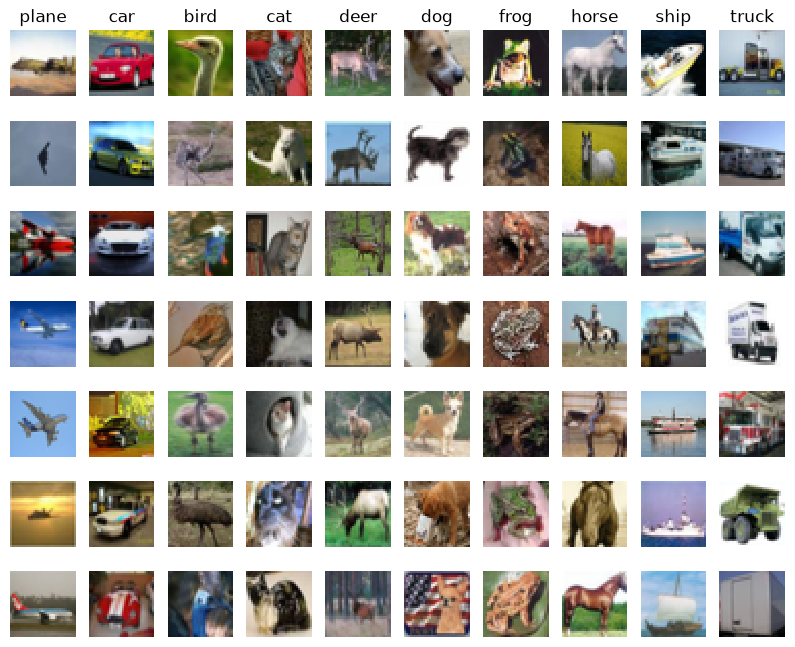

In [7]:
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [8]:
# Subsample the data for more efficient code execution in this exercise
# We use just 1/10 th of the data
num_training = 5000
mask = list(range(num_training))
X_train = X_train[mask]
y_train = y_train[mask]

num_test = 500
mask = list(range(num_test))
X_test = X_test[mask]
y_test = y_test[mask]

In [9]:
# Reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
print(X_train.shape, X_test.shape)

(5000, 3072) (500, 3072)


In [10]:
# If you are using Colab, you will need to run this cell each time you
# change the k_nearest_neighbor file, and uncomment the the commented lines
#import importlib
from k_nearest_neighbor import KNearestNeighbor
#importlib.reload(k_nearest_neighbor)

# Create a kNN classifier instance.
# Remember that training a kNN classifier is a noop:
# the Classifier simply remembers the data and does no further processing
classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

We would now like to classify the test data with the kNN classifier. Recall that we can break down this process into two steps:

1. Phase I of testing: First we must compute the distances between all test examples and all train examples.
2. Phase II of testing: Given these distances, for each test example we find the k nearest examples and have them vote for the label

Lets begin with computing the distance matrix between all training and test examples. For example, if there are **N_tr** training examples and **N_te** test examples, this stage should result in a **N_te x N_tr** matrix where each element $(i,j)$ is the distance between the $i$-th test and $j$-th train example.


#### **Task 1**

First, open `k_nearest_neighbor.py` and implement the function `compute_distances_two_loops` that uses a (very inefficient) double loop over all pairs of (test, train) examples and computes the distance matrix one element at a time.

In [11]:
# TODO
# Open k_nearest_neighbor.py and implement
# compute_distances_two_loops.

# Test your implementation:
dists = classifier.compute_distances_two_loops(X_test)
print("The shape of the distances matrix:", dists.shape)

assert not np.all(dists==0), "ERROR: The function seems to not be implemented, the output is all zeros"
assert np.isclose(dists[0,1],4210.59603857), "ERROR: The function seems to not be correct - an answer does not match with what we got"

The shape of the distances matrix: (500, 5000)


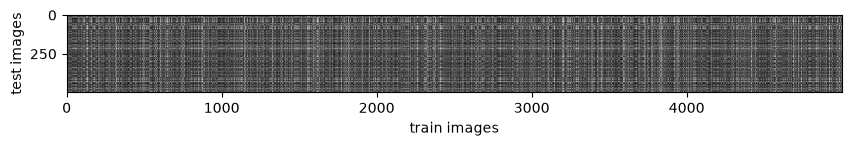

In [9]:
# We can visualize the distance matrix: each row reflects a single test example and
# its distances to training examples
plt.imshow(dists, interpolation='none')
plt.xlabel("train images")
plt.ylabel("test images")
plt.show()

#### **Task 2**

Notice the structured patterns in the distance matrix, where some rows or columns are visible brighter. (Note that with the default color scheme black indicates low distances while white indicates high distances.)

- What in the data is the cause behind the distinctly bright rows?
- What causes the columns?

**Your Answer**: *fill this in.*



#### **Task 3**

Now implement the function `predict_labels` in `k_nearest_neighbor.py` and run the code below:

In [10]:
# We use k = 1 (which is Nearest Neighbor).
y_test_pred = classifier.predict_labels(dists, k=1)

# Compute and print the fraction of correctly predicted examples
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))
assert np.isclose(accuracy,0.274), "The accuracy is not correct, there is some problem"

Got 137 / 500 correct => accuracy: 0.274000


You should expect to see approximately `27%` accuracy. Now lets try out a larger `k`, say `k = 5`:

In [11]:
y_test_pred = classifier.predict_labels(dists, k=5)
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))
assert np.isclose(accuracy,0.278), "The accuracy is not correct, there is some problem"

Got 139 / 500 correct => accuracy: 0.278000


You should expect to see a slightly better performance than with `k = 1`.

#### **Task 4**

Now lets speed up distance matrix computation by using partial vectorization with one loop. Implement the function `compute_distances_one_loop` in `k_nearest_neighbor.py` and run the code below:

In [15]:
dists_one = classifier.compute_distances_one_loop(X_test)

# To ensure that our vectorized implementation is correct, we make sure that it
# agrees with the naive implementation. There are many ways to decide whether
# two matrices are similar; one of the simplest is the Frobenius norm. In case
# you haven't seen it before, the Frobenius norm of two matrices is the square
# root of the squared sum of differences of all elements; in other words, reshape
# the matrices into vectors and compute the Euclidean distance between them.
difference = np.linalg.norm(dists - dists_one, ord='fro')
print('Difference was: %f' % (difference, ))
if difference < 0.001:
    print('Good! The distance matrices are the same')
else:
    print('Uh-oh! The distance matrices are different')

Difference was: 0.000000
Good! The distance matrices are the same


#### **Task 5**

Now implement the fully vectorized version inside `compute_distances_no_loops` in `k_nearest_neighbor.py` and run the code

In [13]:
dists_two = classifier.compute_distances_no_loops(X_test)

# check that the distance matrix agrees with the one we computed before:
difference = np.linalg.norm(dists - dists_two, ord='fro')
print('Difference was: %f' % (difference, ))
if difference < 0.001:
    print('Good! The distance matrices are the same')
else:
    print('Uh-oh! The distance matrices are different')

Difference was: 881644087.112927
Uh-oh! The distance matrices are different


In [16]:
# Let's compare how fast the implementations are
def time_function(f, *args):
    """
    Call a function f with args and return the time (in seconds) that it took to execute.
    """
    import time
    tic = time.time()
    f(*args)
    toc = time.time()
    return toc - tic

two_loop_time = time_function(classifier.compute_distances_two_loops, X_test)
print('Two loop version took %f seconds' % two_loop_time)

one_loop_time = time_function(classifier.compute_distances_one_loop, X_test)
print('One loop version took %f seconds' % one_loop_time)

no_loop_time = time_function(classifier.compute_distances_no_loops, X_test)
print('No loop version took %f seconds' % no_loop_time)

# you should see significantly faster performance with the fully vectorized implementation

Two loop version took 71.201459 seconds
One loop version took 103.040840 seconds
No loop version took 0.677369 seconds


### Cross-validation

We have implemented the k-Nearest Neighbor classifier but we set the value `k = 5` arbitrarily. We will now determine the best value of this hyperparameter with cross-validation.

**Task 6**

In [12]:

num_folds = 5
k_choices = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]

X_train_folds = []
y_train_folds = []
X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

assert np.shape(X_train_folds) == (5, 1000, 3072), "the shape of folds is not correct"

#### **Task 7**

In [13]:

# A dictionary holding the accuracies for different values of k
k_to_accuracies = {}

################################################################################
# Perform k-fold cross validation to find the best value of k
################################################################################

for k in k_choices:
    k_to_accuracies[k] = []

    for fold in range(num_folds):
        X_train_cv = np.concatenate([
            X_train_folds[i]
            for i in range(num_folds)
            if i != fold
        ])

        y_train_cv = np.concatenate([
            y_train_folds[i]
            for i in range(num_folds)
            if i != fold
        ])

        X_val_cv = X_train_folds[fold]
        y_val_cv = y_train_folds[fold]

        classifier = KNearestNeighbor()
        classifier.train(X_train_cv, y_train_cv)

        y_val_pred = classifier.predict(X_val_cv, k=k)

        accuracy = np.mean(y_val_pred == y_val_cv)
        k_to_accuracies[k].append(accuracy)

################################################################################
# Print out the computed accuracies
################################################################################

for k in sorted(k_to_accuracies):
    for accuracy in k_to_accuracies[k]:
        print('k = %d, accuracy = %f' % (k, accuracy))

k = 1, accuracy = 0.103000
k = 1, accuracy = 0.103000
k = 1, accuracy = 0.101000
k = 1, accuracy = 0.099000
k = 1, accuracy = 0.111000
k = 3, accuracy = 0.102000
k = 3, accuracy = 0.101000
k = 3, accuracy = 0.097000
k = 3, accuracy = 0.099000
k = 3, accuracy = 0.109000
k = 5, accuracy = 0.106000
k = 5, accuracy = 0.107000
k = 5, accuracy = 0.102000
k = 5, accuracy = 0.111000
k = 5, accuracy = 0.110000
k = 8, accuracy = 0.104000
k = 8, accuracy = 0.102000
k = 8, accuracy = 0.101000
k = 8, accuracy = 0.102000
k = 8, accuracy = 0.128000
k = 10, accuracy = 0.104000
k = 10, accuracy = 0.100000
k = 10, accuracy = 0.095000
k = 10, accuracy = 0.096000
k = 10, accuracy = 0.127000
k = 12, accuracy = 0.107000
k = 12, accuracy = 0.100000
k = 12, accuracy = 0.098000
k = 12, accuracy = 0.097000
k = 12, accuracy = 0.113000
k = 15, accuracy = 0.103000
k = 15, accuracy = 0.100000
k = 15, accuracy = 0.097000
k = 15, accuracy = 0.098000
k = 15, accuracy = 0.105000
k = 20, accuracy = 0.103000
k = 20, accu

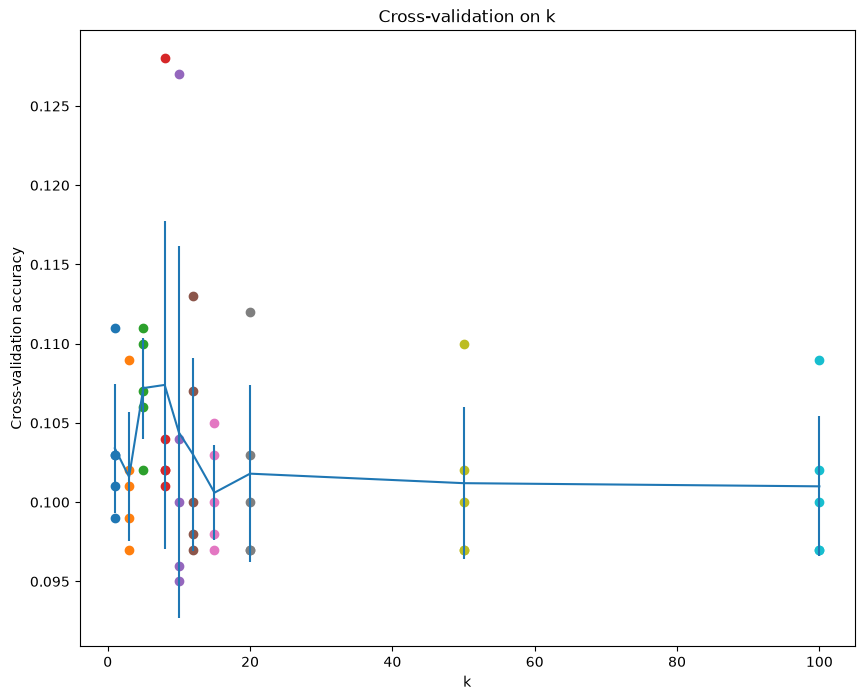

Best k: 8


In [14]:

# Plot the raw observations
for k in k_choices:
    accuracies = k_to_accuracies[k]
    plt.scatter([k] * len(accuracies), accuracies)

# Plot the trend line with error bars
accuracies_mean = np.array([
    np.mean(v) for k, v in sorted(k_to_accuracies.items())
])

accuracies_std = np.array([
    np.std(v) for k, v in sorted(k_to_accuracies.items())
])

plt.errorbar(k_choices, accuracies_mean, yerr=accuracies_std)
plt.title('Cross-validation on k')
plt.xlabel('k')
plt.ylabel('Cross-validation accuracy')
plt.show()

print('Best k:', k_choices[np.argmax(accuracies_mean)])

In [15]:

# Choose the best k based on cross-validation results
best_k = 10  # Replace 10 with the Best k value you got

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

y_test_pred = classifier.predict(X_test, k=best_k)

# Compute and display the accuracy
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 62 / 500 correct => accuracy: 0.124000
